# Corridor activity metrics

Computes one record per corridor for the corridor profile panel and writes the two small files the web app loads at
start-up:

- `corridor_metrics.json`: all metrics, one record per corridor, plus a `meta` block with the shared axes and the
  comparability rules
- `corridor_index.json`: the corridor list (id, display name, the exact name the map's corridor layer uses, centroid,
  district, file names)

## The design principle: separate providers, compare only what is defensible

The data come from three providers (segments **S1** 2019-2022, **S2** Jan-Jun 2023, **S3** 2023H2-2025) with no overlap
and no calibration between them (see `04_cross_segment_comparability`). So:

| Kind of number | How it is stored | Cross-break comparison |
|---|---|---|
| **Monthly activity** | absolute devices/visits as separate S1 and S3 series (S2 = `null`) | none: never join the lines |
| **Within-segment index** | each segment indexed to *its own* first 12 months = 100 | trend and change **inside** a segment (e.g. COVID recovery vs 2019) |
| **Share of the 21-corridor total** | % of the all-corridor total in the same month, which removes the provider's overall scale | allowed, with an explicit uncertainty band (`meta.comparability.share_band_factor`) |
| **Profile metrics** (origin, distance, timing, repeat, district) | one block **per segment** (`segments.S1`, `segments.S3`) | only for metrics that passed the rank-stability test, and then only as **rank position** among the 21 corridors (`peer`), not as raw values |

Raw counts are never written to the output, only sample-weighted estimates and percentages.

---

| | |
|---|---|
| **Inputs** | `data/activity/processed/*` (from `01_`-`04_`) |
| **Outputs** | `src/data/activity/corridor_metrics.json`, `src/data/activity/corridor_index.json` |
| **Run after** | `01_` ... `04_` |

In [1]:
import json
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", message="Unable to import Axes3D")

/home/aniket/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# --- Paths ---
# Repo root = nearest parent folder containing package.json, so this notebook runs from any depth.
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "package.json").exists())
DATA = ROOT / "data"                 # raw + intermediate files
SRC_DATA = ROOT / "src" / "data"     # final outputs consumed directly by the web app
PROCESSED_DIR = DATA / "activity" / "processed"

STOPS_CSV = PROCESSED_DIR / "corridor_stops.csv.gz"
REPEAT_CSV = PROCESSED_DIR / "corridor_repeat_visitors.csv.gz"
HOMES_CSV = PROCESSED_DIR / "corridor_homes.csv.gz"
ORIGIN_CATEGORY_CSV = PROCESSED_DIR / "corridor_origin_categories_monthly.csv.gz"
DISTANCE_CSV = PROCESSED_DIR / "corridor_home_distance_monthly.csv.gz"
HOME_GEOGRAPHY_CSV = PROCESSED_DIR / "home_geography.csv.gz"
PROVIDER_SCHEDULE_CSV = PROCESSED_DIR / "provider_schedule.csv.gz"
BAY_DENOMS_CSV = PROCESSED_DIR / "bay_month_denoms.csv.gz"
CORRIDOR_LOOKUP_CSV = PROCESSED_DIR / "corridor_lookup.csv"
CORRIDOR_DISTRICT_CSV = PROCESSED_DIR / "corridor_districts.csv"
DISTRICT_ORIGIN_CSV = PROCESSED_DIR / "corridor_district_origin.csv"
DISTRICT_ORIGIN_SEGMENT_CSV = PROCESSED_DIR / "corridor_district_origin_by_segment.csv"
COMPARABILITY_JSON = PROCESSED_DIR / "comparability.json"

OUTPUT_DIR = SRC_DATA / "activity"
METRICS_JSON = OUTPUT_DIR / "corridor_metrics.json"
INDEX_JSON = OUTPUT_DIR / "corridor_index.json"

# --- Parameters ---
TIME_PERIODS = ["all", "evening", "nine-five", "weekdays", "weekends"]
PCT_SCALE = 100
UNMATCHED_BG = "UNKNOWN"
ORIGIN_CATEGORIES = ["Oakland", "San Francisco", "Rest East Bay", "Rest Bay Area"]
ORIGIN_CATEGORY_KEYS = {"Oakland": "oakland", "San Francisco": "san_francisco", "Rest East Bay": "rest_east_bay", "Rest Bay Area": "rest_bay_area"}
UNKNOWN_DISTANCE = "Unknown distance"
DISTRICTS = [1, 2, 3, 4, 5, 6, 7]
EARTH_RADIUS_KM = 6371.0088
LOW_SAMPLE_BAY_DEVICES = 50_000      # segments whose reference Bay home panel is smaller than this are flagged low-sample

# Provider segments used (S2 is excluded; see 04_cross_segment_comparability). id -> name in the processed tables
SEGMENTS = {"S1": "S1_LIMA", "S3": "S3_PAPA"}
EXCLUDED_SEGMENTS = {"S2": "S2_SIERRA"}
INDEX_BASE_MONTHS = 12               # each segment's index = 100 at the mean of its first 12 months (also the weights' reference window)
SUMMARY_YEAR = {"S1": "2022", "S3": "2025"}   # last full year of each segment, used for the summary card and peer ranks

# Distance bands, in the data's native order: (output label, lo km, hi km), half-open [lo, hi)
DISTANCE_BANDS = [("0-2", 0, 2), ("2-5", 2, 5), ("5-10", 5, 10), ("10-25", 10, 25), ("25-50", 25, 50), ("50-100", 50, 100), ("100+", 100, np.inf)]
DISTANCE_LABELS = [b[0] for b in DISTANCE_BANDS]

# comparability.json keys -> short metric ids used in this file
METRIC_KEYS = {
    "Share of 21-corridor total (devices)": "devices_share",
    "Oakland share of visitors": "oakland_pct",
    "Share of visitors within 5 km": "within_5km_pct",
    "Share of visitors beyond 25 km": "beyond_25km_pct",
    "Weekend share of visits": "weekend_pct",
    "Evening share (evening vs weekday daytime)": "evening_pct",
    "Repeat-visitor %": "repeat_pct",
    "Share from corridor's own council district": "in_district_pct",
}

# --- Chart styling (see dataviz skill: fixed categorical order, single-hue sequential) ---
CATEGORICAL_PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEG_COLORS = {"S1": CATEGORICAL_PALETTE[0], "S3": CATEGORICAL_PALETTE[2]}
SEQUENTIAL_BLUE_RAMP = ["#cde2fb", "#9ec3f2", "#6da7ec", "#2a78d6", "#1f62b4", "#184f95", "#0f3563"]
CHART_GRID_COLOR = "#e1e0d9"
CHART_MUTED_TEXT = "#898781"

In [3]:
def style_axis(ax, grid_axis="y"):
    """Shared cosmetic cleanup: recessive grid, no top/right spines."""
    ax.grid(axis=grid_axis, color=CHART_GRID_COLOR, linewidth=0.6, zorder=0)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.tick_params(colors=CHART_MUTED_TEXT)


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = np.radians(lat1), np.radians(lon1), np.radians(lat2), np.radians(lon2)
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))


def weighted_quantile(values, weights, q):
    """Weighted quantile (lower interpolation): smallest value whose cumulative weight reaches q."""
    order = np.argsort(values)
    v, w = np.asarray(values)[order], np.asarray(weights)[order]
    cum = np.cumsum(w) / w.sum()
    return float(v[np.searchsorted(cum, q)])


def clean_band(label):
    """'02: 5-10 km' (with en dash) -> '5-10'."""
    return re.sub(r"^\d+:\s*", "", label).replace("\u2013", "-").replace(" km", "").strip()


def num(x, ndigits=1):
    return None if pd.isna(x) else round(float(x), ndigits)


def to_list(series, ndigits=1, as_int=False):
    """Series -> JSON list with None for missing."""
    return [None if pd.isna(v) else (int(round(v)) if as_int else round(float(v), ndigits)) for v in series]

## Load data and the provider timeline

In [4]:
stops = pd.read_csv(STOPS_CSV)
stops["year_month"] = stops.year_month.astype(str)
repeat = pd.read_csv(REPEAT_CSV)
origin_cat = pd.read_csv(ORIGIN_CATEGORY_CSV)
origin_cat["year_month"] = origin_cat.year_month.astype(str)
distance = pd.read_csv(DISTANCE_CSV)
distance["year_month"] = distance.year_month.astype(str)
lookup = pd.read_csv(CORRIDOR_LOOKUP_CSV)
corridor_districts = pd.read_csv(CORRIDOR_DISTRICT_CSV).set_index("corridor_slug")
district_pooled = pd.read_csv(DISTRICT_ORIGIN_CSV)
district_seg = pd.read_csv(DISTRICT_ORIGIN_SEGMENT_CSV)
schedule = pd.read_csv(PROVIDER_SCHEDULE_CSV)
schedule["year_month"] = schedule.year_month.astype(str)
bay_denoms = pd.read_csv(BAY_DENOMS_CSV)
with open(COMPARABILITY_JSON) as f:
    comp = json.load(f)

slugs = lookup.corridor_slug.tolist()                       # set 1 then set 2, the display order
months = sorted(schedule.year_month.unique())
half_years = sorted(repeat.half_year.unique())
seg_short = schedule.set_index("year_month").provider_segment.str.split("_").str[0]
month_seg = seg_short.reindex(months)                       # S1 / S2 / S3 for every month
hy_seg = repeat.drop_duplicates("half_year").set_index("half_year").provider_segment.str.split("_").str[0].reindex(half_years)

seg_months = {sid: [m for m in months if month_seg[m] == sid] for sid in ["S1", "S2", "S3"]}
active_months = [m for m in months if month_seg[m] in SEGMENTS]
panel = bay_denoms.assign(seg=bay_denoms.provider_segment.str.split("_").str[0]).groupby("seg").baseline_bay_home_sample.first()

segments_meta = [
    {
        "id": sid, "start": ms[0], "end": ms[-1],
        "reference_bay_home_devices": int(round(panel[sid])),
        "status": "used" if sid in SEGMENTS else "excluded",
        "low_sample": bool(panel[sid] < LOW_SAMPLE_BAY_DEVICES),
    }
    for sid, ms in seg_months.items()
]
print(f"{len(slugs)} corridors, {len(months)} months ({months[0]}-{months[-1]}), {len(half_years)} half-years")
pd.DataFrame(segments_meta)

21 corridors, 84 months (201901-202512), 14 half-years


,id,start,end,reference_bay_home_devices,status,low_sample
0,S1,201901,202212,211000,used,False
1,S2,202301,202306,16718,excluded,True
2,S3,202307,202512,2291930,used,False


## Metric 1: monthly activity (three views of the same series)

From `corridor_stops`, the `adjusted_known_home_*` columns: devices with a matched Bay Area home, re-weighted by that
month's home-sample index. Excluded-segment months are `null`.

1. **`devices` / `visits`** (absolute, per segment): for drawing S1 and S3 as separate lines. **Never joined.**
2. **`index`**: each segment indexed to the mean of **its own first 12 months = 100**. Because the weights are anchored on that
   same reference window, the index is the like-for-like way to follow change *inside* a segment (e.g. recovery from the
   2019 level in S1).
3. **`share_of_total`**: the corridor's % of the sum of all 21 corridors in the same month and period. A change of
   provider multiplies every corridor by roughly the same overall factor, so the *share* is far more stable across the break
   than the level (see `04_`), but not perfectly; `meta.comparability.share_band_factor` carries the width of the
   uncertainty band to draw across the break.

In [5]:
def monthly_frame(period, col):
    f = stops[stops.time_period == period].pivot(index="year_month", columns="corridor_slug", values=col).reindex(months)[slugs]
    f.loc[[m for m in months if m not in active_months]] = np.nan          # excluded segment -> gap
    return f


dev = {p: monthly_frame(p, "adjusted_known_home_unique_devices") for p in TIME_PERIODS}
vis_all = monthly_frame("all", "adjusted_known_home_visits")

# within-segment index: base = mean of the segment's first INDEX_BASE_MONTHS months
index = {}
for p in TIME_PERIODS:
    idx = pd.DataFrame(np.nan, index=months, columns=slugs)
    for sid in SEGMENTS:
        ms = seg_months[sid]
        base = dev[p].loc[ms[:INDEX_BASE_MONTHS]].mean()
        idx.loc[ms] = dev[p].loc[ms] / base * 100
    index[p] = idx

share = {p: dev[p].div(dev[p].sum(axis=1), axis=0) * PCT_SCALE for p in TIME_PERIODS}

band = comp["level"]["share_of_total"]["excess_sd_log"]
share_band_factor = float(np.exp(band))
print(f"Share-of-total uncertainty band across the break: x / {share_band_factor:.2f} to x * {share_band_factor:.2f}")
print(f"Missing (null) corridor x period x month values: {sum(int(dev[p].isna().sum().sum()) for p in TIME_PERIODS)} (= excluded S2 months: {len(seg_months['S2'])} x {len(slugs)} x {len(TIME_PERIODS)} = {len(seg_months['S2']) * len(slugs) * len(TIME_PERIODS)})")

Share-of-total uncertainty band across the break: x / 1.42 to x * 1.42
Missing (null) corridor x period x month values: 630 (= excluded S2 months: 6 x 21 x 5 = 630)


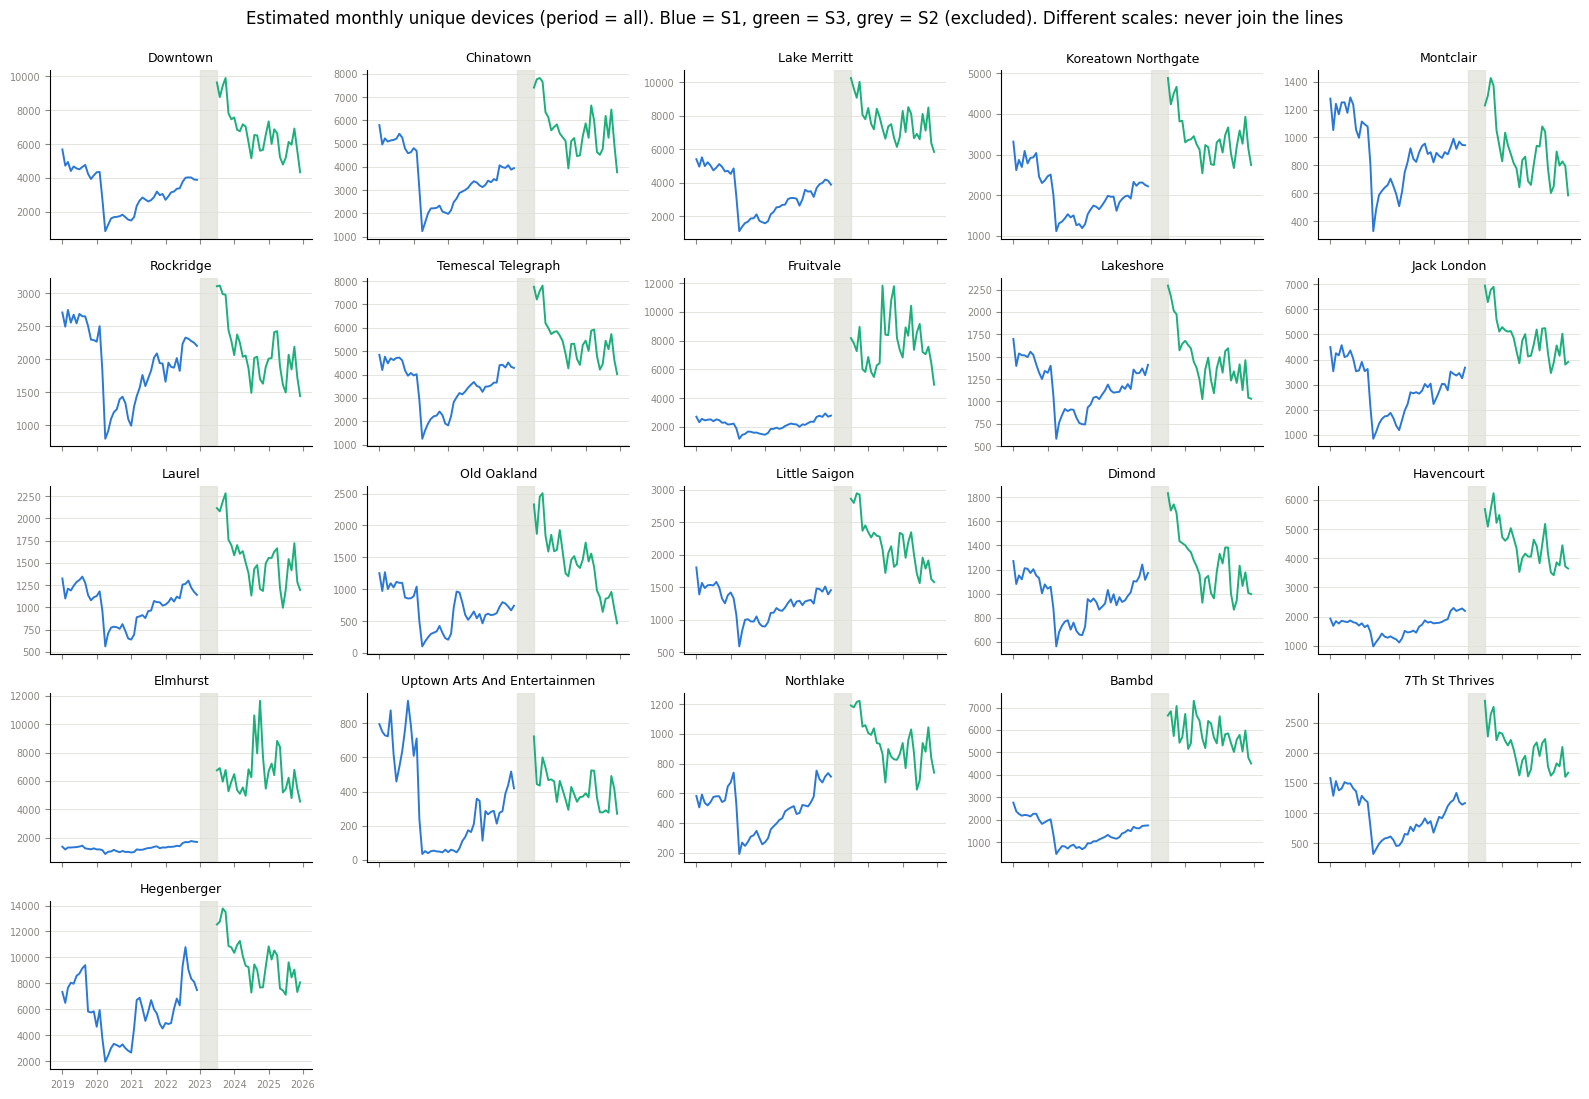

In [6]:
# Chart 1: absolute devices (period = all) as separate S1 and S3 lines, one panel per corridor
months_dt = pd.to_datetime(months, format="%Y%m")
fig, axes = plt.subplots(5, 5, figsize=(16, 11), sharex=True)
for ax, slug in zip(axes.flat, slugs):
    for sid, color in SEG_COLORS.items():
        ms = seg_months[sid]
        ax.plot(pd.to_datetime(ms, format="%Y%m"), dev["all"].loc[ms, slug], color=color, linewidth=1.4)
    ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2023-06-30"), color=CHART_GRID_COLOR, alpha=0.7, zorder=0)
    ax.set_title(slug.replace("_", " ").title()[:28], fontsize=9)
    ax.tick_params(labelsize=7, colors=CHART_MUTED_TEXT)
    style_axis(ax)
for ax in list(axes.flat)[len(slugs):]:
    ax.set_visible(False)
plt.suptitle("Estimated monthly unique devices (period = all). Blue = S1, green = S3, grey = S2 (excluded). Different scales: never join the lines", y=0.995)
plt.tight_layout()
plt.show()

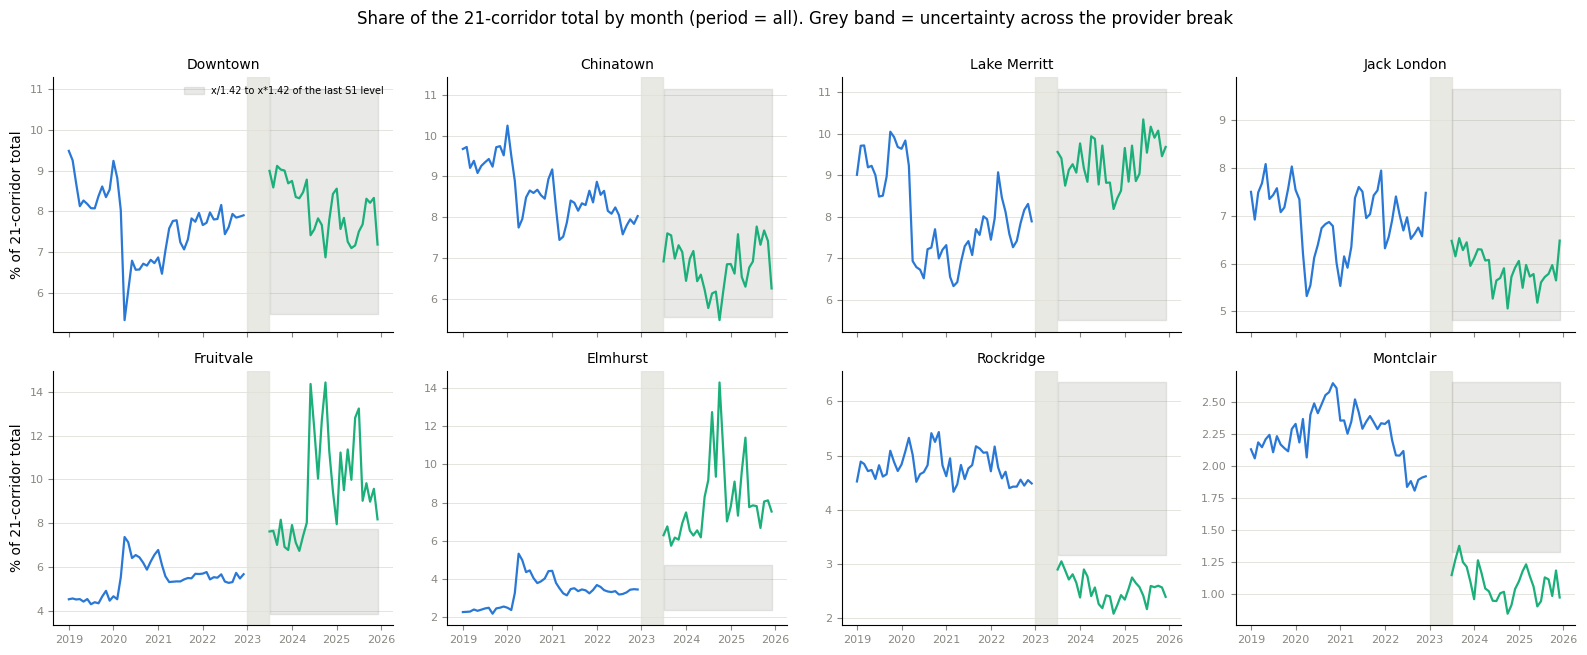

In [7]:
# Chart 2: share of the 21-corridor total, with the break band, for a selection of corridors
sample = ["downtown", "chinatown", "lake_merritt", "jack_london", "fruitvale", "elmhurst", "rockridge", "montclair"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
for ax, slug in zip(axes.flat, sample):
    s = share["all"][slug]
    last_s1 = s.loc[seg_months["S1"][-6:]].mean()                  # S1 level in the final half-year
    ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2023-06-30"), color=CHART_GRID_COLOR, alpha=0.7, zorder=0)
    ax.fill_between([pd.Timestamp("2023-07-01"), months_dt[-1]], last_s1 / share_band_factor, last_s1 * share_band_factor, color=CHART_MUTED_TEXT, alpha=0.18, zorder=1, label=f"x/{share_band_factor:.2f} to x*{share_band_factor:.2f} of the last S1 level")
    for sid, color in SEG_COLORS.items():
        ms = seg_months[sid]
        ax.plot(pd.to_datetime(ms, format="%Y%m"), s.loc[ms], color=color, linewidth=1.6)
    ax.set_title(slug.replace("_", " ").title(), fontsize=10)
    ax.tick_params(labelsize=8, colors=CHART_MUTED_TEXT)
    style_axis(ax)
axes[0, 0].set_ylabel("% of 21-corridor total")
axes[1, 0].set_ylabel("% of 21-corridor total")
axes[0, 0].legend(frameon=False, fontsize=7, loc="upper right")
plt.suptitle("Share of the 21-corridor total by month (period = all). Grey band = uncertainty across the provider break", y=1.0)
plt.tight_layout()
plt.show()

## Metric 2: repeat visitors

`repeat_device_prop` is the share of a corridor's devices seen on at least two different days within the half-year
(unweighted; counts reset every six months). Stored per half-year, `null` for the excluded 2023H1. **It is
within-segment only**: the S3 provider records fewer pings per device, so repeat rates fall by about a third at the
S2/S3 boundary in every corridor, and the corridor ranking does not survive the break (rho 0.3 in `04_`).

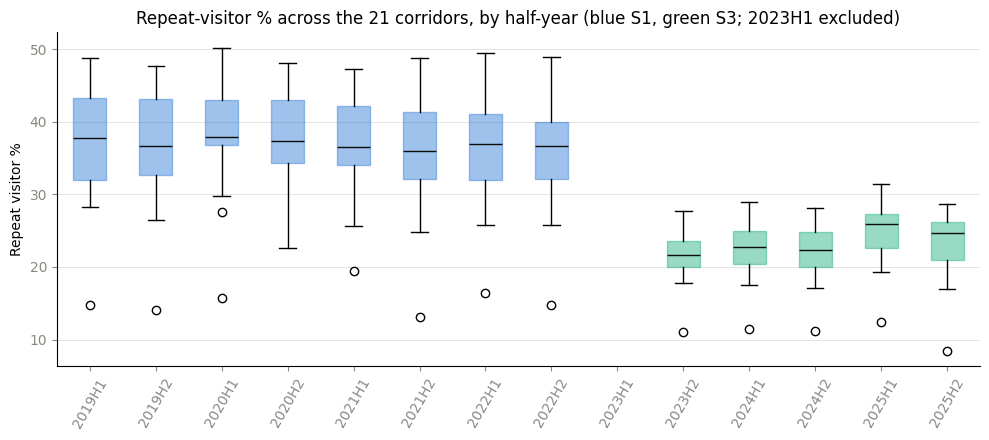

In [8]:
rep = repeat.copy()
rep.loc[rep.provider_segment.isin(EXCLUDED_SEGMENTS.values()), "repeat_device_prop"] = np.nan
repeat_pct = {}
for slug, grp in rep.groupby("corridor_slug"):
    repeat_pct[slug] = {p: to_list(grp[grp.time_period == p].set_index("half_year").reindex(half_years).repeat_device_prop * PCT_SCALE, 2) for p in TIME_PERIODS}

# Chart: distribution across corridors by half-year (period = all); the step at the break is the provider
r_all = rep[rep.time_period == "all"].assign(pct=lambda d: d.repeat_device_prop * PCT_SCALE)
fig, ax = plt.subplots(figsize=(10, 4.5))
bp = ax.boxplot([r_all.loc[r_all.half_year == h, "pct"].dropna() if r_all.loc[r_all.half_year == h, "pct"].notna().any() else [np.nan] for h in half_years],
                tick_labels=half_years, patch_artist=True, medianprops={"color": "#0b0b0b"})
for b, h in zip(bp["boxes"], half_years):
    c = SEG_COLORS.get(hy_seg[h], CHART_MUTED_TEXT)
    b.set(facecolor=c, alpha=0.45, edgecolor=c)
ax.set_title("Repeat-visitor % across the 21 corridors, by half-year (blue S1, green S3; 2023H1 excluded)")
ax.set_ylabel("Repeat visitor %")
ax.tick_params(axis="x", rotation=60)
style_axis(ax)
plt.tight_layout()
plt.show()

## Per-segment profile metrics

Everything below is computed **separately inside S1 and S3**, so each block is a self-contained, single-provider
description. Metrics:

- **Timing splits**: weekday/weekend and weekday-daytime/evening share of (weighted) visits
- **Origin by area**: Oakland / San Francisco / rest of East Bay / rest of Bay Area share of matched-home device-months
- **Origin by council district**: share from each district and from the corridor's own (primary) district
- **Travel distance**: share in each distance band, plus median and mean distance (home block-group centre to corridor centroid)
- **Repeat %** (mean of the segment's half-years)

In [9]:
def seg_rows(df, sid):
    return df[df.year_month.isin(seg_months[sid])]


# --- timing splits ---
split_tot = {
    sid: seg_rows(stops[stops.time_period.isin(["weekdays", "weekends", "nine-five", "evening"])], sid)
    .groupby(["corridor_slug", "time_period"]).adjusted_known_home_visits.sum().unstack().reindex(slugs)
    for sid in SEGMENTS
}
splits = {}
for sid, t in split_tot.items():
    splits[sid] = {
        s: {
            "weekday_pct": num(t.loc[s, "weekdays"] / (t.loc[s, "weekdays"] + t.loc[s, "weekends"]) * PCT_SCALE, 2),
            "weekend_pct": num(t.loc[s, "weekends"] / (t.loc[s, "weekdays"] + t.loc[s, "weekends"]) * PCT_SCALE, 2),
            "nine_five_pct": num(t.loc[s, "nine-five"] / (t.loc[s, "nine-five"] + t.loc[s, "evening"]) * PCT_SCALE, 2),
            "evening_pct": num(t.loc[s, "evening"] / (t.loc[s, "nine-five"] + t.loc[s, "evening"]) * PCT_SCALE, 2),
        }
        for s in slugs
    }

# --- origin by area ---
oc = origin_cat[origin_cat.home_geography.isin(ORIGIN_CATEGORIES)]
origin_area = {}
for sid in SEGMENTS:
    g = seg_rows(oc, sid).groupby(["corridor_slug", "time_period", "home_geography"]).normalized_unique_devices.sum().unstack("home_geography").reindex(columns=ORIGIN_CATEGORIES).fillna(0)
    pct = g.div(g.sum(axis=1), axis=0) * PCT_SCALE
    origin_area[sid] = {s: {p: {ORIGIN_CATEGORY_KEYS[c]: num(pct.loc[(s, p), c], 2) for c in ORIGIN_CATEGORIES} for p in TIME_PERIODS} for s in slugs}

# --- distance bands ---
dk = distance[distance.distance_band != UNKNOWN_DISTANCE].copy()
dk["band"] = dk.distance_band.map(clean_band)
assert set(dk.band) == set(DISTANCE_LABELS), set(dk.band)
bands = {}
for sid in SEGMENTS:
    g = seg_rows(dk, sid).groupby(["corridor_slug", "time_period", "band"]).normalized_unique_devices.sum().unstack("band").reindex(columns=DISTANCE_LABELS).fillna(0)
    bands[sid] = g.div(g.sum(axis=1), axis=0) * PCT_SCALE

In [10]:
# --- median / mean distance from the half-year home table ---
homes = pd.read_csv(HOMES_CSV, dtype={"block_group_id": str}, usecols=["corridor_slug", "time_period", "block_group_id", "provider_segment", "normalized_unique_device_months"])
homes = homes[(homes.block_group_id != UNMATCHED_BG) & homes.provider_segment.isin(SEGMENTS.values())]
homes["segment"] = homes.provider_segment.str.split("_").str[0]
home_geo = pd.read_csv(HOME_GEOGRAPHY_CSV, dtype={"geoid": str})
homes = homes.merge(home_geo[["block_group_id", "home_lat", "home_lon"]], on="block_group_id", how="left").merge(lookup[["corridor_slug", "lat", "lon"]], on="corridor_slug", how="left")
assert homes[["home_lat", "lat"]].notna().all().all()
homes["distance_km"] = haversine_km(homes.home_lat, homes.home_lon, homes.lat, homes.lon)

homes_agg = homes.groupby(["corridor_slug", "time_period", "segment", "block_group_id"], as_index=False).agg(w=("normalized_unique_device_months", "sum"), d=("distance_km", "first"))
dist_stats = {}
for (slug, period, sid), g in tqdm(homes_agg.groupby(["corridor_slug", "time_period", "segment"]), desc="median distance"):
    dist_stats[(slug, period, sid)] = {"median_km": weighted_quantile(g.d.values, g.w.values, 0.5), "mean_km": float(np.average(g.d.values, weights=g.w.values))}

# QA: bands implied by our haversine distances vs the band table
edges = [b[1] for b in DISTANCE_BANDS] + [np.inf]
homes_agg["band"] = pd.cut(homes_agg.d, bins=edges, right=False, labels=DISTANCE_LABELS)
qa = homes_agg.groupby(["segment", "corridor_slug", "time_period", "band"], observed=False).w.sum().unstack("band")
qa = qa.div(qa.sum(axis=1), axis=0) * PCT_SCALE
gaps = [(qa.loc[sid] - bands[sid].reindex(qa.loc[sid].index)).abs().max().max() for sid in SEGMENTS]
print(f"QA: max gap between band shares from haversine distances and the band table: {max(gaps):.2f} points")

travel = {
    sid: {
        s: {p: {"median_km": num(dist_stats[(s, p, sid)]["median_km"], 2), "mean_km": num(dist_stats[(s, p, sid)]["mean_km"], 2),
                "bands": [num(bands[sid].loc[(s, p), b], 2) for b in DISTANCE_LABELS]} for p in TIME_PERIODS}
        for s in slugs
    }
    for sid in SEGMENTS
}

median distance:   0%|          | 0/210 [00:00<?, ?it/s]

QA: max gap between band shares from haversine distances and the band table: 0.00 points


In [11]:
# --- council-district origin (per segment, and the equal-weight blend the map uses) ---
primary = corridor_districts.primary_district.reindex(slugs)
touched = {s: [int(d) for d in str(corridor_districts.loc[s, "touched_districts"]).split(",") if d != ""] for s in slugs}


def district_block(df, slug_col="corridor_slug"):
    w = df.pivot_table(index=[slug_col, "time_period"], columns="district", values="pct").reindex(columns=DISTRICTS)
    out = {}
    for s in slugs:
        out[s] = {
            "in_district_pct": {p: num(w.loc[(s, p), int(primary[s])], 2) for p in TIME_PERIODS},
            "by_district": {p: [num(w.loc[(s, p), d], 2) for d in DISTRICTS] for p in TIME_PERIODS},       # order = meta.districts
        }
    return out


district = {sid: district_block(district_seg[district_seg.segment == sid]) for sid in SEGMENTS}
district_pooled_block = district_block(district_pooled)

# --- repeat % per segment ---
repeat_seg = {}
for sid in SEGMENTS:
    hys = [h for h in half_years if hy_seg[h] == sid]
    g = rep[rep.half_year.isin(hys)].groupby(["corridor_slug", "time_period"]).repeat_device_prop.mean() * PCT_SCALE
    repeat_seg[sid] = {s: {p: num(g.get((s, p)), 2) for p in TIME_PERIODS} for s in slugs}

## Summary card values and peer positions

Per segment, over its **last full year** (S1: 2022, S3: 2025; each is wholly inside one provider):

- devices per month, visits per device, repeat %, median travel distance, Oakland share, own-district share;
- the corridor's **share of the 21-corridor total** in that year.

**Peer position** (`peer`): for each metric, the corridor's **rank among the 21** (1 = highest) and its **gap to the
median corridor**, both computed *inside the segment*. Metrics that passed the rank-stability test in `04_` (rule
`peer_relative`) also get a `peer_change`: how many rank places a corridor moved between S1 and S3 (positive = moved
up). Metrics that failed carry the within-segment rank but never a cross-break change.

In [12]:
rules = {METRIC_KEYS[m]: v["rule"] for m, v in comp["rank_stability"].items()}
print("Cross-segment rules:", rules)

peer_values = {}
for sid in SEGMENTS:
    yr = SUMMARY_YEAR[sid]
    yr_months = [m for m in seg_months[sid] if m.startswith(yr)]
    b = bands[sid].xs("all", level="time_period").reindex(slugs)
    rep_hys = [h for h in half_years if h.startswith(yr)]
    r = rep[(rep.time_period == "all") & rep.half_year.isin(rep_hys)].groupby("corridor_slug").repeat_device_prop.mean() * PCT_SCALE
    peer_values[sid] = pd.DataFrame({
        "devices_share": share["all"].loc[yr_months].mean().reindex(slugs),
        "oakland_pct": pd.Series({s: origin_area[sid][s]["all"]["oakland"] for s in slugs}),
        "within_5km_pct": b[DISTANCE_LABELS[:2]].sum(axis=1),
        "beyond_25km_pct": b[DISTANCE_LABELS[4:]].sum(axis=1),
        "weekend_pct": pd.Series({s: splits[sid][s]["weekend_pct"] for s in slugs}),
        "evening_pct": pd.Series({s: splits[sid][s]["evening_pct"] for s in slugs}),
        "repeat_pct": r.reindex(slugs),
        "in_district_pct": pd.Series({s: district[sid][s]["in_district_pct"]["all"] for s in slugs}),
    })

peer = {}
for sid, pv in peer_values.items():
    rank = pv.rank(ascending=False, method="min").astype(int)
    gap = pv - pv.median()
    peer[sid] = {s: {m: {"value": num(pv.loc[s, m], 2), "rank": int(rank.loc[s, m]), "gap_to_median": num(gap.loc[s, m], 2)} for m in pv.columns} for s in slugs}

peer_change = {}
for s in slugs:
    peer_change[s] = {
        m: int(peer["S1"][s][m]["rank"] - peer["S3"][s][m]["rank"]) for m in peer_values["S1"].columns if rules[m] == "peer_relative"
    }
    # share of total changes are additionally given in percentage points, with the band factor in meta
    peer_change[s]["devices_share_pts"] = num(peer_values["S3"].loc[s, "devices_share"] - peer_values["S1"].loc[s, "devices_share"], 2)

summary = {}
for sid in SEGMENTS:
    yr = SUMMARY_YEAR[sid]
    yr_idx = [m for m in seg_months[sid] if m.startswith(yr)]
    rep_hys = [h for h in half_years if h.startswith(yr)]
    summary[sid] = {}
    for s in slugs:
        d_, v_ = dev["all"].loc[yr_idx, s], vis_all.loc[yr_idx, s]
        summary[sid][s] = {
            "year": int(yr),
            "devices_per_month": int(round(d_.mean())),
            "visits_per_device": num(v_.sum() / d_.sum(), 2),
            "repeat_pct": num(peer_values[sid].loc[s, "repeat_pct"], 1),
            "median_travel_km": travel[sid][s]["all"]["median_km"],
            "oakland_origin_pct": origin_area[sid][s]["all"]["oakland"],
            "in_district_pct": district[sid][s]["in_district_pct"]["all"],
            "devices_share_pct": num(peer_values[sid].loc[s, "devices_share"], 2),
        }

view = pd.DataFrame({f"{m} ({sid})": peer_values[sid][m] for sid in SEGMENTS for m in ["oakland_pct", "within_5km_pct"]}).round(1)
view.insert(0, "devices/month S3", [summary["S3"][s]["devices_per_month"] for s in view.index])
view.sort_values("devices/month S3", ascending=False)

Cross-segment rules: {'devices_share': 'peer_relative', 'oakland_pct': 'peer_relative', 'within_5km_pct': 'peer_relative', 'beyond_25km_pct': 'peer_relative', 'weekend_pct': 'within_segment_only', 'evening_pct': 'within_segment_only', 'repeat_pct': 'within_segment_only', 'in_district_pct': 'within_segment_only'}


,devices/month S3,oakland_pct (S1),within_5km_pct (S1),oakland_pct (S3),within_5km_pct (S3)
hegenberger,8843,26.7,22.1,39.8,33.7
fruitvale,7730,57.4,47.2,52.7,43.6
lake_merritt,7331,31.0,24.1,42.7,35.7
elmhurst,6333,59.1,53.9,54.8,49.8
downtown,5919,28.7,21.4,40.9,32.5
bambd,5472,35.1,23.7,50.2,40.5
chinatown,5363,29.4,26.5,38.5,34.3
temescal_telegraph,5054,31.3,28.6,41.0,36.0
jack_london,4424,27.9,20.7,36.5,29.7
havencourt,4034,60.7,54.3,65.0,58.9


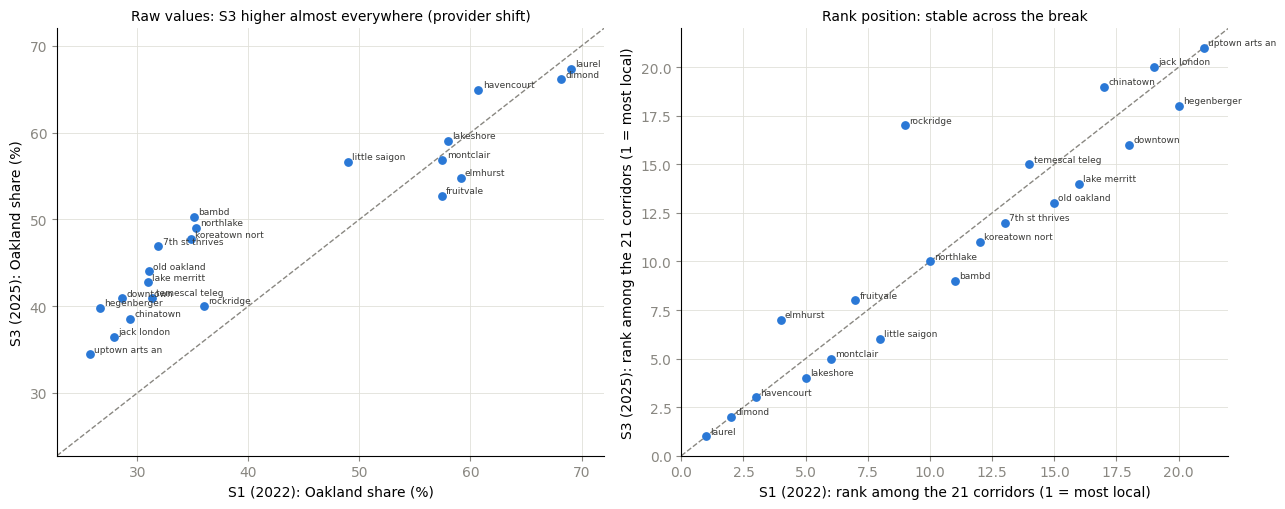

In [13]:
# Chart: Oakland share, S1 vs S3 as peer rank (passes the rule) and as raw values (does not carry across)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
pv1, pv3 = peer_values["S1"], peer_values["S3"]
for ax, kind in zip(axes, ["raw", "rank"]):
    if kind == "raw":
        x, y, lab = pv1.oakland_pct, pv3.oakland_pct, "Oakland share (%)"
        lim = [min(x.min(), y.min()) - 3, max(x.max(), y.max()) + 3]
        ax.plot(lim, lim, color=CHART_MUTED_TEXT, linestyle="--", linewidth=1)
        ax.set_title("Raw values: S3 higher almost everywhere (provider shift)", fontsize=10)
    else:
        x, y = pv1.oakland_pct.rank(ascending=False), pv3.oakland_pct.rank(ascending=False)
        lab, lim = "rank among the 21 corridors (1 = most local)", [0, 22]
        ax.plot(lim, lim, color=CHART_MUTED_TEXT, linestyle="--", linewidth=1)
        ax.set_title("Rank position: stable across the break", fontsize=10)
    ax.scatter(x, y, color=CATEGORICAL_PALETTE[0], s=28, zorder=3)
    for s in slugs:
        ax.annotate(s.replace("_", " ")[:14], (x[s], y[s]), xytext=(3, 2), textcoords="offset points", fontsize=6.5, color="#3a3a38")
    ax.set_xlabel(f"S1 (2022): {lab}"); ax.set_ylabel(f"S3 (2025): {lab}")
    ax.set_xlim(lim); ax.set_ylim(lim)
    style_axis(ax, "both")
plt.tight_layout()
plt.show()

## Assemble and write the output JSON

`corridor_index.json` is the list the UI iterates over. Each entry carries `id` (slug used in file names), `name`,
`map_name` (the corridor's `corridor_name` **exactly as in `OAK_CORRIDORS.geo.json`**, with any odd whitespace, so
the front end can look up `index.by_map_name[feature.properties.corridor_name]`; `null` if the corridor is not drawn
on the map, currently only Hegenberger), `centroid` ([lon, lat]), district and the origin-map file names for the
three variants.

`corridor_metrics.json` has `meta` (shared axes, segment definitions, the comparability rules and band) and `corridors`
(a dictionary keyed by corridor id).

In [14]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

meta = {
    "months": months,
    "half_years": half_years,
    "segments": segments_meta,
    "time_periods": TIME_PERIODS,
    "distance_bands": DISTANCE_LABELS,
    "districts": DISTRICTS,
    "summary_year": SUMMARY_YEAR,
    "comparability": {
        "rules": rules,                                         # per metric: "peer_relative" (rank position may be compared across S1/S3) or "within_segment_only"
        "share_band_factor": round(share_band_factor, 3),      # a corridor's share of total may differ by x/factor .. x*factor across the break
        "rank_ok_threshold": comp["rank_ok_threshold"],
        "pooling_reliability": comp["pooling_reliability"],
        "notes": {
            "segments": "S1 (2019-2022) and S3 (Jul 2023-2025) are different providers with no overlap and no calibration. S2 (Jan-Jun 2023) is excluded: ~17k-device panel. "
                        "Never join S1 and S3 absolute levels, repeat %, evening share, weekend share or own-district share.",
            "monthly": "Estimated unique devices / visits with a matched Bay Area home, re-weighted by that month's home sample. Excluded months are null.",
            "index": "Each segment indexed to the mean of its own first 12 months = 100. Compare inside a segment only.",
            "share_of_total": "% of the sum over the 21 corridors in the same month and period. Comparable across the break within the stated band.",
            "peer": "rank (1 = highest of 21) and gap to the median corridor, computed inside each segment; peer_change = rank places moved S1 -> S3 for peer_relative metrics.",
            "shares": "All origin, district and distance values are % of the corridor's matched-home device-months in that segment.",
        },
    },
}

corridors = {}
for slug in tqdm(slugs, desc="assembling"):
    row = lookup.set_index("corridor_slug").loc[slug]
    corridors[slug] = {
        "id": slug,
        "name": row.corridor_name,
        "primary_district": int(primary[slug]),
        "touched_districts": touched[slug],
        "monthly": {p: {"devices": to_list(dev[p][slug], as_int=True), **({"visits": to_list(vis_all[slug], as_int=True)} if p == "all" else {})} for p in TIME_PERIODS},
        "index": {p: to_list(index[p][slug], 1) for p in TIME_PERIODS},
        "share_of_total": {p: to_list(share[p][slug], 2) for p in TIME_PERIODS},
        "repeat_pct": repeat_pct[slug],
        "segments": {
            sid: {
                "summary": summary[sid][slug],
                "splits": splits[sid][slug],
                "origin_by_area": origin_area[sid][slug],
                "district_origin": district[sid][slug],
                "travel_distance": travel[sid][slug],
                "repeat_pct": repeat_seg[sid][slug],
                "peer": peer[sid][slug],
            }
            for sid in SEGMENTS
        },
        "pooled": {"district_origin": district_pooled_block[slug]},          # S1/S3 equal-weight blend, same basis as the map files
        "peer_change": peer_change[slug],
    }

with open(METRICS_JSON, "w") as f:
    json.dump({"meta": meta, "corridors": corridors}, f, separators=(",", ":"))

index_rows = []
for slug in slugs:
    row = lookup.set_index("corridor_slug").loc[slug]
    cd = corridor_districts.loc[slug]
    index_rows.append({
        "id": slug,
        "name": row.corridor_name,
        "map_name": None if pd.isna(cd.raw_map_name) else cd.raw_map_name,
        "in_map": bool(cd.in_map),
        "corridor_set": int(row.corridor_set),
        "centroid": [round(float(row.lon), 6), round(float(row.lat), 6)],
        "primary_district": int(cd.primary_district),
        "area_hectares": float(cd.area_hectares),
        "origin_files": {
            "pooled": f"corridor_home_origin/corridor_{slug}.json",
            "S1": f"corridor_home_origin_s1/corridor_{slug}.json",
            "S3": f"corridor_home_origin_s3/corridor_{slug}.json",
        },
    })
with open(INDEX_JSON, "w") as f:
    json.dump(index_rows, f, indent=2, ensure_ascii=True)

print(f"Wrote {METRICS_JSON.relative_to(ROOT)} ({METRICS_JSON.stat().st_size / 1024:.0f} KB) and {INDEX_JSON.relative_to(ROOT)} ({INDEX_JSON.stat().st_size / 1024:.1f} KB)")

assembling:   0%|          | 0/21 [00:00<?, ?it/s]

Wrote src/data/activity/corridor_metrics.json (258 KB) and src/data/activity/corridor_index.json (9.8 KB)


In [15]:
# Sanity: round-trip, array lengths, S2 months are null, and preview one record (arrays shortened)
loaded = json.load(open(METRICS_JSON))
cs = loaded["corridors"]
assert len(cs) == len(slugs)
s2_idx = [months.index(m) for m in seg_months["S2"]]
for c in cs.values():
    for p in TIME_PERIODS:
        for arr in [c["monthly"][p]["devices"], c["index"][p], c["share_of_total"][p]]:
            assert len(arr) == len(months)
            assert all(arr[i] is None for i in s2_idx), "S2 months must be null"
            assert all(arr[i] is not None for i in range(len(months)) if i not in s2_idx)
        assert len(c["repeat_pct"][p]) == len(half_years)
print("array lengths and S2 gaps OK")

preview = json.loads(json.dumps(cs["fruitvale"]))
for k in ["monthly", "index", "share_of_total"]:
    for p in list(preview[k]):
        if p != "all":
            del preview[k][p]
for p in preview["monthly"]:
    for m in preview["monthly"][p]:
        preview["monthly"][p][m] = preview["monthly"][p][m][:3] + ["..."]
for k in ["index", "share_of_total"]:
    preview[k]["all"] = preview[k]["all"][:3] + ["..."]
preview["repeat_pct"] = {"all": preview["repeat_pct"]["all"]}
for sid in preview["segments"]:
    seg = preview["segments"][sid]
    seg["origin_by_area"] = {"all": seg["origin_by_area"]["all"]}
    seg["travel_distance"] = {"all": seg["travel_distance"]["all"]}
    seg["district_origin"] = {"in_district_pct": {"all": seg["district_origin"]["in_district_pct"]["all"]}}
    seg["peer"] = {k: seg["peer"][k] for k in list(seg["peer"])[:2]}
    seg["repeat_pct"] = {"all": seg["repeat_pct"]["all"]}
preview["pooled"] = "..."
print(json.dumps(preview, indent=1)[:3800])

idx = json.load(open(INDEX_JSON))
print("\nNot on the map:", [e["id"] for e in idx if not e["in_map"]])
print("map_name values with odd whitespace:", [repr(e["map_name"]) for e in idx if e["map_name"] and e["map_name"] != e["map_name"].strip()])

array lengths and S2 gaps OK
{
 "id": "fruitvale",
 "name": "Fruitvale",
 "primary_district": 5,
 "touched_districts": [
  5
 ],
 "monthly": {
  "all": {
   "devices": [
    2706,
    2324,
    2557,
    "..."
   ],
   "visits": [
    7065,
    5695,
    6582,
    "..."
   ]
  }
 },
 "index": {
  "all": [
   111.2,
   95.5,
   105.1,
   "..."
  ]
 },
 "share_of_total": {
  "all": [
   4.52,
   4.55,
   4.51,
   "..."
  ]
 },
 "repeat_pct": {
  "all": [
   46.49,
   46.13,
   47.94,
   46.08,
   45.74,
   46.21,
   46.01,
   45.64,
   null,
   20.31,
   24.7,
   26.56,
   30.71,
   25.6
  ]
 },
 "segments": {
  "S1": {
   "summary": {
    "year": 2022,
    "devices_per_month": 2489,
    "visits_per_device": 2.5,
    "repeat_pct": 45.8,
    "median_travel_km": 5.28,
    "oakland_origin_pct": 57.4,
    "in_district_pct": 16.94,
    "devices_share_pct": 5.53
   },
   "splits": {
    "weekday_pct": 71.34,
    "weekend_pct": 28.66,
    "nine_five_pct": 62.53,
    "evening_pct": 37.47
   },
 